# Flood-onset early warning for Sri Lankan rivers: LightGBM + Logistic Regression blend
**Question:** if a river point is *below* its high-flow level today, will it go *above* it within the next 3 days?

This notebook runs the whole pipeline in order: data, training, blending, comparison graphs, accuracy check, explainability (SHAP and partial dependence), and saving the model used by the Streamlit app.

Run it top to bottom (Kernel → Restart & Run All). It reads `data/onset_table.csv`, which `src/prepare.py` builds from the GloFAS NetCDF files.

In [9]:
%pip install joblib shap lightgbm interpret scikit-learn pandas numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [10]:
import json, pathlib, warnings, itertools, numpy as np, pandas as pd, joblib, shap
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, f1_score,
    precision_score, recall_score, matthews_corrcoef, confusion_matrix, accuracy_score, balanced_accuracy_score)
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore"); SEED = 42
cwd = pathlib.Path.cwd(); ROOT = cwd.parent if cwd.name == "notebooks" else cwd
(ROOT/"figures").mkdir(exist_ok=True); (ROOT/"models").mkdir(exist_ok=True); (ROOT/"outputs").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
COL = {"Logistic Regression": "#E4572E", "LightGBM": "#4C78A8", "Blend (LightGBM + Logistic)": "#2E933C"}
def savefig(name): plt.tight_layout(); plt.savefig(ROOT/"figures"/name, dpi=160, bbox_inches="tight")
print("project folder:", ROOT)

project folder: /Users/sajivininagendran/Downloads/glofas 2


## 1. Data and time-based split
Train = earliest period, validation = used to choose settings, test = latest period, used once for the final score. A random split would leak the future, because river flow on consecutive days is almost identical.

In [11]:
FEATS = ["q_over_thr","lag1_over_thr","lag2_over_thr","lag3_over_thr","lag7_over_thr","mean7_over_thr","mean30_over_thr","max7_over_thr","rise_1d","rise_3d","q_over_mean30"]
NICE = {"q_over_thr":"Flow today / high-flow level","lag1_over_thr":"Flow 1 day ago / level","lag2_over_thr":"Flow 2 days ago / level","lag3_over_thr":"Flow 3 days ago / level",
        "lag7_over_thr":"Flow 7 days ago / level","mean7_over_thr":"7-day mean / level","mean30_over_thr":"30-day mean / level","max7_over_thr":"7-day max / level",
        "rise_1d":"1-day relative rise","rise_3d":"3-day relative rise","q_over_mean30":"Flow today / 30-day mean"}
df = pd.read_csv(ROOT/"data"/"onset_table.csv", parse_dates=["date"])
for a, b in (("q_lag1","lag1_over_thr"),("q_lag2","lag2_over_thr"),("q_lag3","lag3_over_thr"),("q_lag7","lag7_over_thr"),("q_mean7","mean7_over_thr"),("q_mean30","mean30_over_thr"),("q_max7","max7_over_thr")):
    df[b] = df[a] / df["thr"]
tr, va, te = [df[df.split == s] for s in ("train", "valid", "test")]
Xtr, ytr, Xva, yva, Xte, yte = tr[FEATS], tr.y, va[FEATS], va.y, te[FEATS], te.y
summary = df.groupby("split").agg(days=("y","size"), onsets=("y","sum"), onset_rate=("y","mean"), first_day=("date","min"), last_day=("date","max")).loc[["train","valid","test"]]
summary["onset_rate"] = (summary.onset_rate * 100).round(2).astype(str) + " %"
summary

,days,onsets,onset_rate,first_day,last_day
split,,,,,
train,15559,352,2.26 %,2024-01-31,2025-06-30
valid,4923,162,3.29 %,2025-07-01,2025-12-31
test,9536,100,1.05 %,2026-01-01,2026-10-22


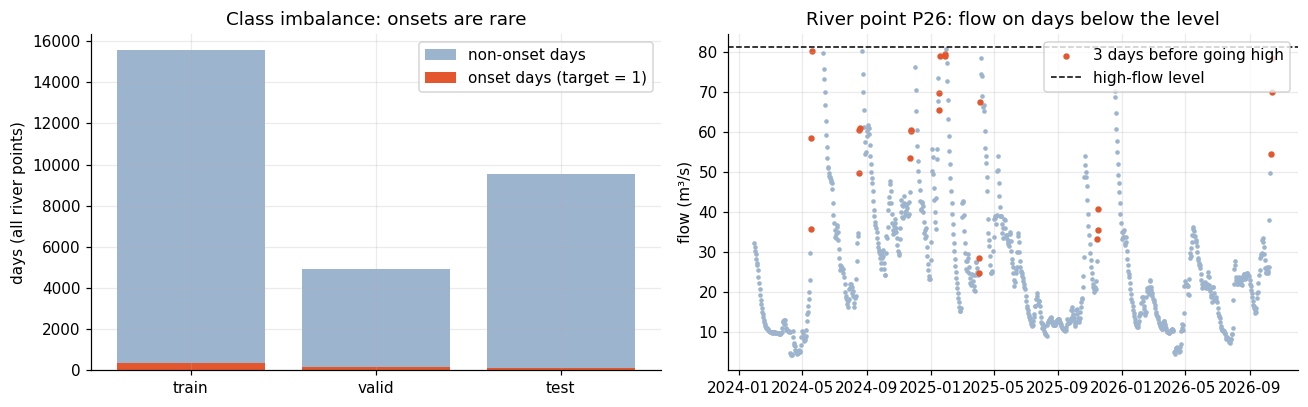

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s = summary.copy(); s["onsets"] = s["onsets"].astype(int)
ax[0].bar(s.index, s.days, color="#9DB4CF", label="non-onset days"); ax[0].bar(s.index, s.onsets, color="#E4572E", label="onset days (target = 1)")
ax[0].set_title("Class imbalance: onsets are rare"); ax[0].set_ylabel("days (all river points)"); ax[0].legend()
pid = tr.groupby("point_id").y.sum().idxmax(); p1 = df[df.point_id == pid].sort_values("date")
ax[1].scatter(p1.date, p1.q, s=4, color="#9DB4CF"); ax[1].scatter(p1.date[p1.y == 1], p1.q[p1.y == 1], s=10, color="#E4572E", label="3 days before going high")
ax[1].axhline(p1.thr.iloc[0], color="k", ls="--", lw=1, label="high-flow level"); ax[1].set_title(f"River point {pid}: flow on days below the level"); ax[1].set_ylabel("flow (m³/s)"); ax[1].legend()
savefig("nb_01_data_overview.png"); plt.show()

## 2. Train the two models
Both use `class_weight` / `scale_pos_weight` so the rare onsets are not ignored. Settings are chosen on the **validation** period only (PR-AUC), then the alert threshold is chosen on validation to maximise F1.

In [13]:
pos_w = (ytr == 0).sum() / (ytr == 1).sum()
def best_thr(y, p):
    pr, rc, th = precision_recall_curve(y, p); f = 2*pr*rc/(pr+rc+1e-12); return float(th[np.nanargmax(f[:-1])])
def scores(y, p, thr):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y, yh), balanced_accuracy=balanced_accuracy_score(y, yh), precision=precision_score(y, yh, zero_division=0),
                recall=recall_score(y, yh), f1=f1_score(y, yh), pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p), mcc=matthews_corrcoef(y, yh), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))
def tune(make, grid):
    out = []
    for p in grid:
        m = make(**p).fit(Xtr, ytr); out.append((average_precision_score(yva, m.predict_proba(Xva)[:,1]), p, m))
    return sorted(out, key=lambda t: -t[0])
lr_runs = tune(lambda **p: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, **p)), [dict(C=c) for c in (0.01, 0.1, 1, 10)])
lgb_runs = tune(lambda **p: LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=4, scale_pos_weight=pos_w, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, **p),
                [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, min_child_samples=30) for n, lr, nl in itertools.product((150, 400), (0.03, 0.08), (8, 16))])
lr_model, lgb_model = lr_runs[0][2], lgb_runs[0][2]
print("Logistic Regression best:", lr_runs[0][1], " valid PR-AUC = %.3f" % lr_runs[0][0])
print("LightGBM best:           ", lgb_runs[0][1], " valid PR-AUC = %.3f" % lgb_runs[0][0])
pd.DataFrame([dict(model="LightGBM", **p, valid_pr_auc=round(a, 3)) for a, p, _ in lgb_runs]).head(8)

Logistic Regression best: {'C': 10}  valid PR-AUC = 0.418
LightGBM best:            {'n_estimators': 150, 'learning_rate': 0.03, 'num_leaves': 8, 'min_child_samples': 30}  valid PR-AUC = 0.412


,model,n_estimators,learning_rate,num_leaves,min_child_samples,valid_pr_auc
0,LightGBM,150,0.03,8,30,0.412
1,LightGBM,150,0.03,16,30,0.385
2,LightGBM,150,0.08,8,30,0.379
3,LightGBM,400,0.03,8,30,0.363
4,LightGBM,400,0.03,16,30,0.327
5,LightGBM,150,0.08,16,30,0.307
6,LightGBM,400,0.08,8,30,0.306
7,LightGBM,400,0.08,16,30,0.264


## 3. Blend the two models
Blend probability = `w` × LightGBM + (1 − `w`) × Logistic Regression. The weight `w` is chosen on the **validation** period; the test period is not used to choose it.

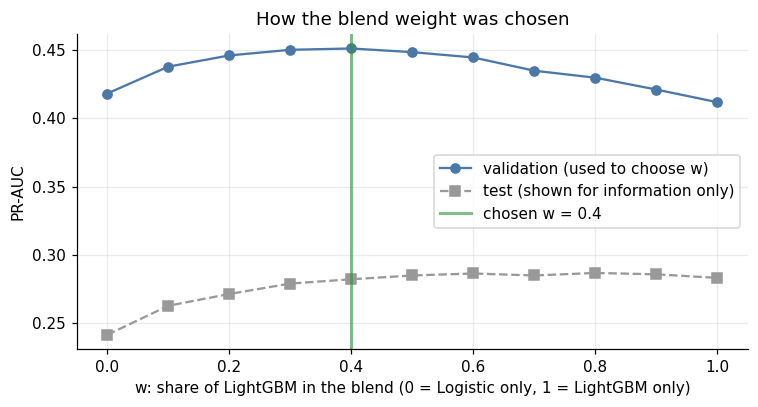

Chosen weight: 0.4 LightGBM + 0.6 Logistic


In [14]:
P = {s: {"Logistic Regression": lr_model.predict_proba(X)[:,1], "LightGBM": lgb_model.predict_proba(X)[:,1]} for s, X in (("valid", Xva), ("test", Xte))}
ws = np.round(np.arange(0, 1.01, 0.1), 1)
curve = pd.DataFrame({"w (LightGBM share)": ws,
    "valid PR-AUC": [average_precision_score(yva, w*P["valid"]["LightGBM"] + (1-w)*P["valid"]["Logistic Regression"]) for w in ws],
    "test PR-AUC":  [average_precision_score(yte, w*P["test"]["LightGBM"]  + (1-w)*P["test"]["Logistic Regression"])  for w in ws]})
W = float(ws[int(curve["valid PR-AUC"].values.argmax())])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ws, curve["valid PR-AUC"], "o-", color="#4C78A8", label="validation (used to choose w)"); ax.plot(ws, curve["test PR-AUC"], "s--", color="#999", label="test (shown for information only)")
ax.axvline(W, color="#2E933C", lw=2, alpha=.6, label=f"chosen w = {W}"); ax.set_xlabel("w: share of LightGBM in the blend (0 = Logistic only, 1 = LightGBM only)"); ax.set_ylabel("PR-AUC"); ax.legend()
ax.set_title("How the blend weight was chosen"); savefig("nb_02_blend_weight.png"); plt.show()
for s in P: P[s]["Blend (LightGBM + Logistic)"] = W*P[s]["LightGBM"] + (1-W)*P[s]["Logistic Regression"]
print(f"Chosen weight: {W} LightGBM + {round(1-W,1)} Logistic")

## 4. Compare the models (validation and test)

In [15]:
NAMES = list(COL)
THR = {n: best_thr(yva, P["valid"][n]) for n in NAMES}
R = {n: {"valid": scores(yva, P["valid"][n], THR[n]), "test": scores(yte, P["test"][n], THR[n])} for n in NAMES}
never = lambda y: dict(accuracy=1 - y.mean(), balanced_accuracy=0.5, precision=0.0, recall=0.0, f1=0.0, pr_auc=y.mean(), roc_auc=0.5)
cols = ["accuracy","balanced_accuracy","precision","recall","f1","pr_auc","roc_auc","mcc"]
table = pd.DataFrame({(s, n): {c: R[n][s][c] for c in cols} for s in ("valid","test") for n in NAMES}).T
table.loc[("test", "Never alert (reference)")] = pd.Series({**never(yte), "mcc": 0.0})
table.round(3)

accuracy  balanced_accuracy  precision  \
valid Logistic Regression             0.969              0.689      0.543   
      LightGBM                        0.964              0.731      0.453   
      Blend (LightGBM + Logistic)     0.966              0.726      0.490   
test  Logistic Regression             0.984              0.666      0.291   
      LightGBM                        0.963              0.749      0.148   
      Blend (LightGBM + Logistic)     0.975              0.715      0.198   

                                   recall     f1  pr_auc  roc_auc    mcc  \
valid Logistic Regression           0.389  0.453   0.418    0.897  0.444   
      LightGBM                      0.481  0.467   0.412    0.871  0.449   
      Blend (LightGBM + Logistic)   0.469  0.479   0.451    0.901  0.462   
test  Logistic Regression           0.340  0.313   0.241    0.891  0.306   
      LightGBM                      0.530  0.231   0.283    0.899  0.266   
      Blend (LightGBM + Logistic)   0.450  0.275   0.282    0.905  0.288   

                                   Never alert (reference)  
valid Logistic Regression                              NaN  
      LightGBM                                         NaN  
      Blend (LightGBM + Logistic)                      NaN  
test  Logistic Regression                              NaN  
      LightGBM                                         NaN  
      Blend (LightGBM + Logistic)                      NaN

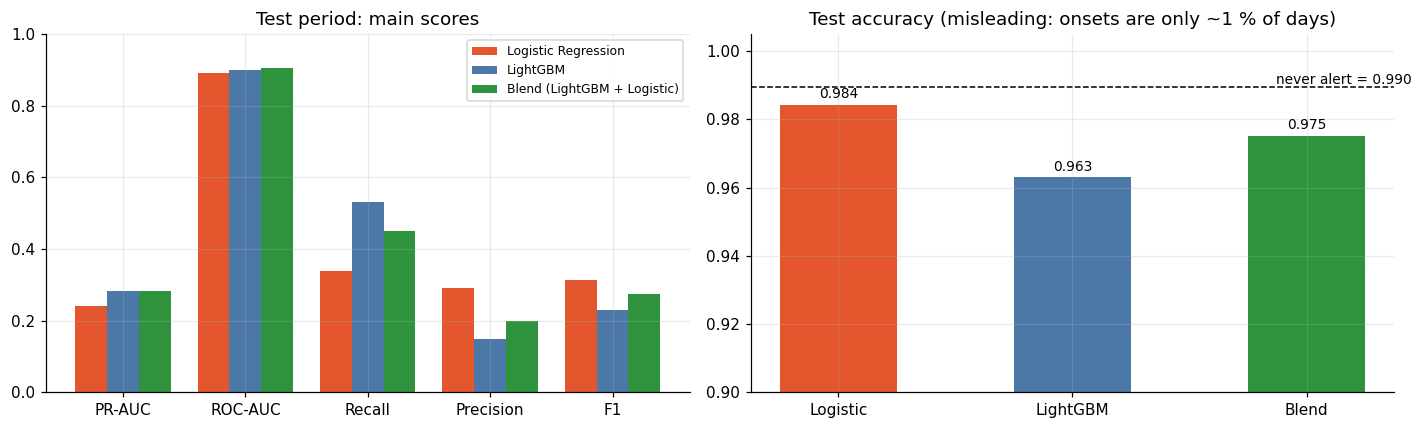

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
met = ["pr_auc","roc_auc","recall","precision","f1"]; x = np.arange(len(met)); wd = .26
for i, n in enumerate(NAMES): ax[0].bar(x + (i-1)*wd, [R[n]["test"][m] for m in met], wd, label=n, color=COL[n])
ax[0].set_xticks(x); ax[0].set_xticklabels(["PR-AUC","ROC-AUC","Recall","Precision","F1"]); ax[0].set_ylim(0, 1); ax[0].set_title("Test period: main scores"); ax[0].legend(fontsize=8)
for i, n in enumerate(NAMES):
    ax[1].bar(i, R[n]["test"]["accuracy"], .5, color=COL[n]); ax[1].text(i, R[n]["test"]["accuracy"] + .002, f'{R[n]["test"]["accuracy"]:.3f}', ha="center", fontsize=9)
ax[1].axhline(1 - yte.mean(), color="k", ls="--", lw=1); ax[1].text(2.45, 1 - yte.mean() + .001, "never alert = %.3f" % (1 - yte.mean()), ha="right", fontsize=9)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["Logistic", "LightGBM", "Blend"]); ax[1].set_ylim(.9, 1.005); ax[1].set_title("Test accuracy (misleading: onsets are only ~1 % of days)")
savefig("nb_03_metrics_and_accuracy.png"); plt.show()

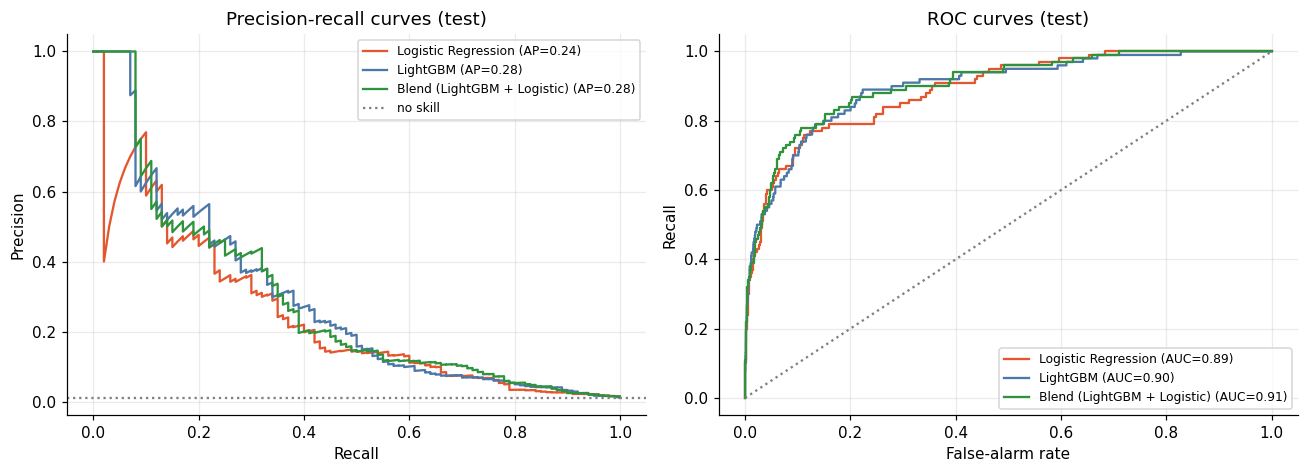

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for n in NAMES:
    pr, rc, _ = precision_recall_curve(yte, P["test"][n]); ax[0].plot(rc, pr, color=COL[n], label=f'{n} (AP={R[n]["test"]["pr_auc"]:.2f})')
    fpr, tpr, _ = roc_curve(yte, P["test"][n]); ax[1].plot(fpr, tpr, color=COL[n], label=f'{n} (AUC={R[n]["test"]["roc_auc"]:.2f})')
ax[0].axhline(yte.mean(), color="grey", ls=":", label="no skill"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-recall curves (test)"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], color="grey", ls=":"); ax[1].set_xlabel("False-alarm rate"); ax[1].set_ylabel("Recall"); ax[1].set_title("ROC curves (test)"); ax[1].legend(fontsize=8)
savefig("nb_04_pr_roc_curves.png"); plt.show()

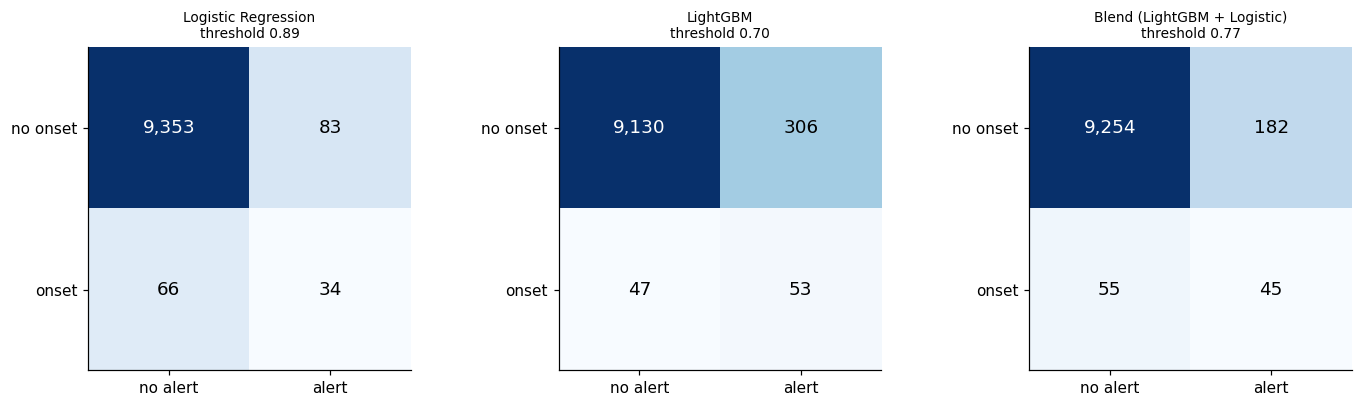

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, n in zip(axs, NAMES):
    r = R[n]["test"]; cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]]); ax.imshow(cm, cmap="Blues", norm="log"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=12, color="white" if v > 500 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["no alert", "alert"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["no onset", "onset"]); ax.set_title(f"{n}\nthreshold {THR[n]:.2f}", fontsize=9)
savefig("nb_05_confusion_matrices.png"); plt.show()

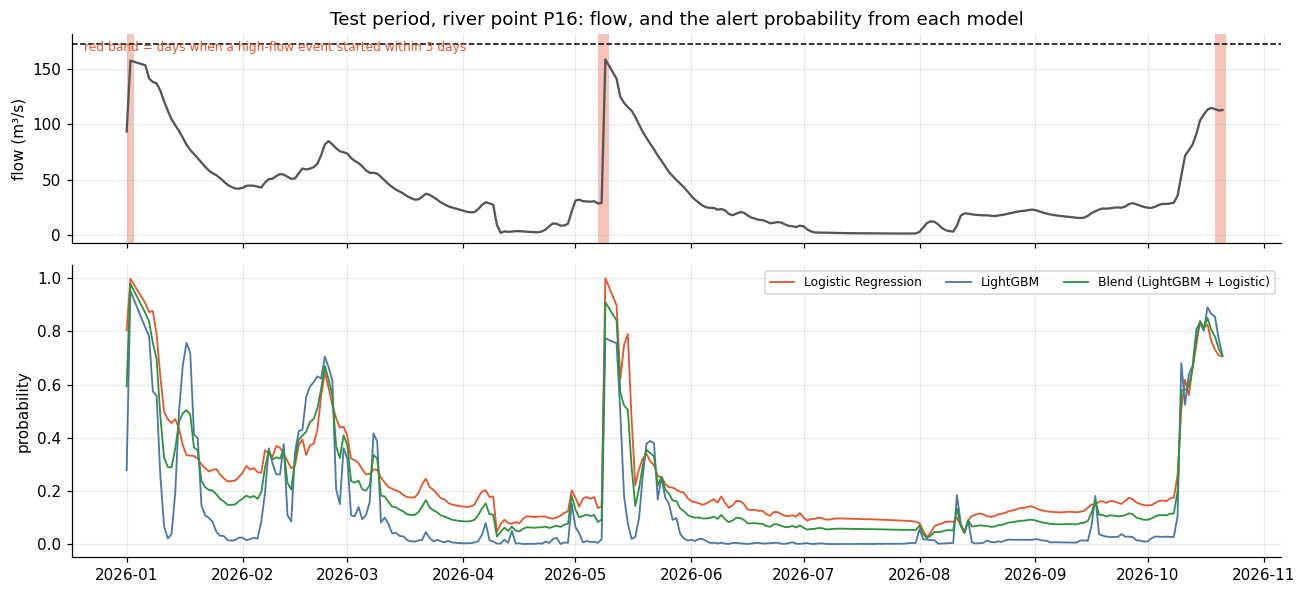

In [19]:
pid = te.groupby("point_id").y.sum().idxmax(); idx = np.where(te.point_id.values == pid)[0]; d = te.date.values[idx]
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
ax[0].plot(d, te.q.values[idx], color="#555"); ax[0].axhline(te.thr.values[idx][0], color="k", ls="--", lw=1); ax[0].set_ylabel("flow (m³/s)"); ax[0].set_title(f"Test period, river point {pid}: flow, and the alert probability from each model")
for k in np.where(yte.values[idx] == 1)[0]: ax[0].axvspan(d[k], d[k] + np.timedelta64(1, "D"), color="#E4572E", alpha=.35, lw=0)
for n in NAMES: ax[1].plot(d, P["test"][n][idx], color=COL[n], label=n, lw=1.2)
ax[1].set_ylabel("probability"); ax[1].legend(fontsize=8, ncol=3); ax[0].text(0.01, .92, "red band = days when a high-flow event started within 3 days", transform=ax[0].transAxes, fontsize=8, color="#E4572E")
savefig("nb_06_probability_over_time.png"); plt.show()

## 5. Explainability
SHAP explains LightGBM. Logistic Regression is explained directly by its coefficients. Partial dependence compares all three models.

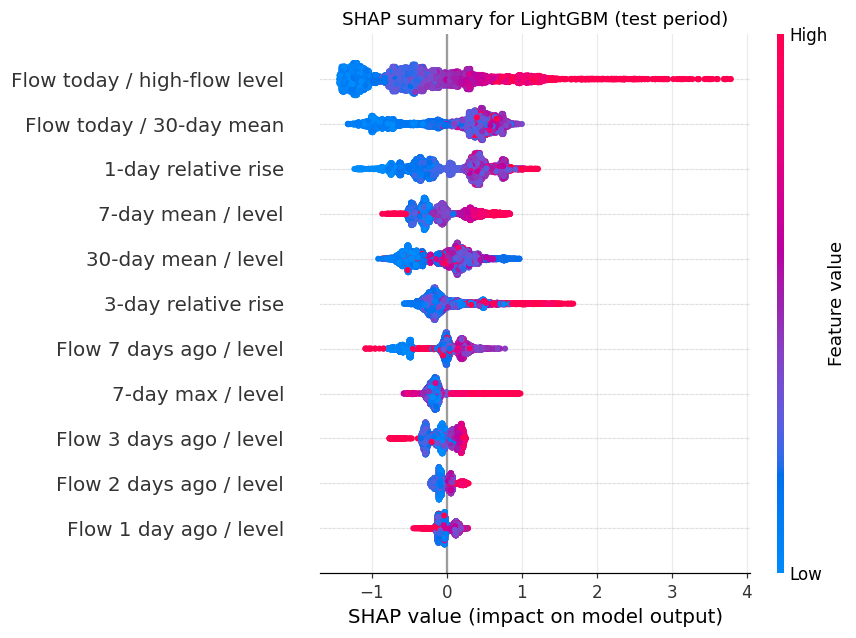

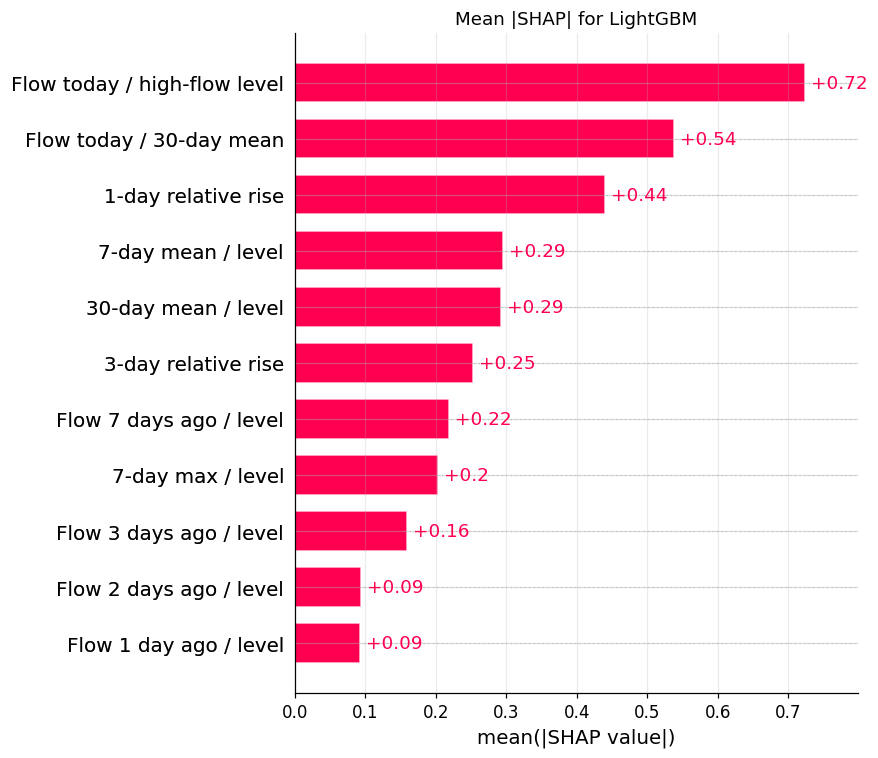

Flow today / high-flow level    0.724
Flow today / 30-day mean        0.538
1-day relative rise             0.439
7-day mean / level              0.295
30-day mean / level             0.293
3-day relative rise             0.252
Flow 7 days ago / level         0.218
7-day max / level               0.203
Flow 3 days ago / level         0.160
Flow 2 days ago / level         0.094
Flow 1 day ago / level          0.093
dtype: float64

In [20]:
expl = shap.TreeExplainer(lgb_model); sv = expl(Xte)
vals = sv.values if sv.values.ndim == 2 else sv.values[:, :, 1]
base = float(np.ravel(sv.base_values)[0])
exp = shap.Explanation(values=vals, base_values=np.full(len(Xte), base), data=Xte.rename(columns=NICE).values, feature_names=[NICE[c] for c in FEATS])
imp = pd.Series(np.abs(vals).mean(0), index=[NICE[c] for c in FEATS]).sort_values(ascending=False)
shap.plots.beeswarm(exp, show=False, max_display=11); plt.title("SHAP summary for LightGBM (test period)"); savefig("nb_07_shap_beeswarm.png"); plt.show()
shap.plots.bar(exp, show=False, max_display=11); plt.title("Mean |SHAP| for LightGBM"); savefig("nb_08_shap_bar.png"); plt.show()
imp.round(3)

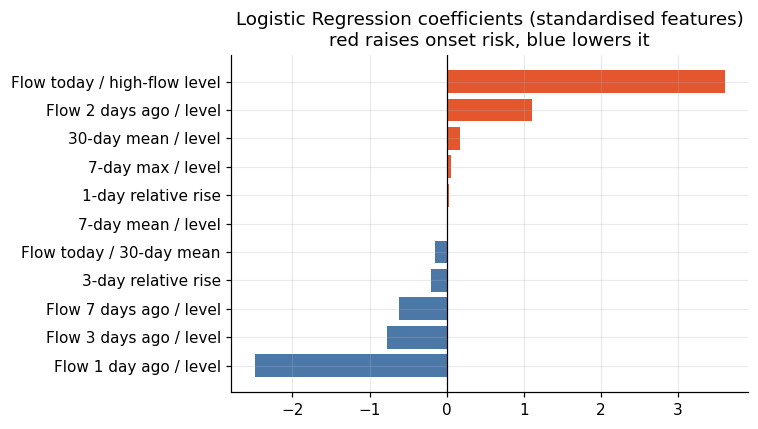

In [21]:
coef = pd.Series(lr_model[-1].coef_[0], index=[NICE[c] for c in FEATS]).sort_values()
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, "#E4572E", "#4C78A8")); ax.axvline(0, color="k", lw=.8)
ax.set_title("Logistic Regression coefficients (standardised features)\nred raises onset risk, blue lowers it"); savefig("nb_09_logistic_coefficients.png"); plt.show()

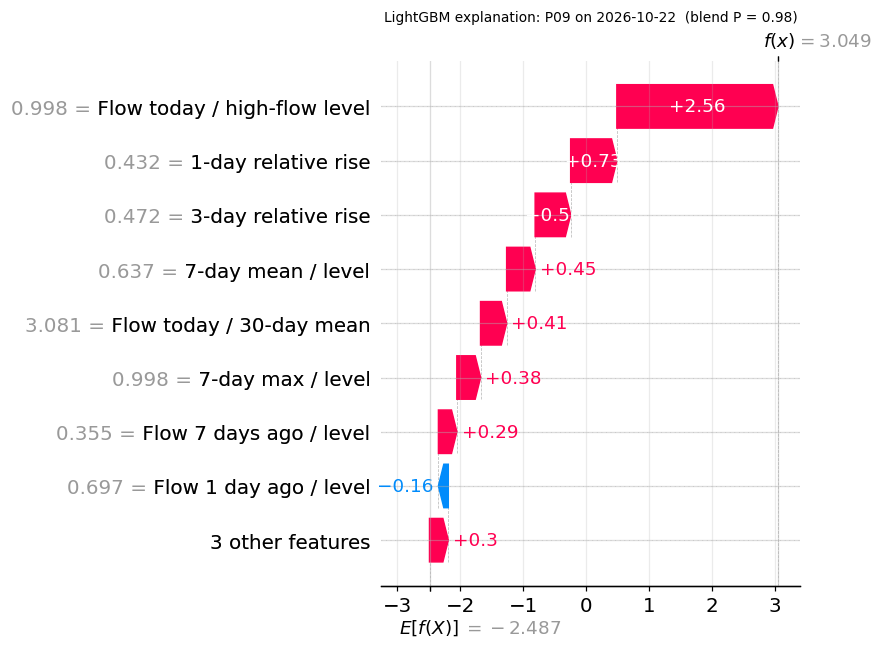

In [22]:
# Local explanation: the highest-risk true onset in the test period, according to the blend
pb = P["test"]["Blend (LightGBM + Logistic)"]; cand = np.where(yte.values == 1)[0]; i = int(cand[np.argmax(pb[cand])])
shap.plots.waterfall(exp[i], show=False, max_display=9); plt.title(f"LightGBM explanation: {te.point_id.values[i]} on {te.date.values[i].astype('datetime64[D]')}  (blend P = {pb[i]:.2f})", fontsize=9)
savefig("nb_10_shap_waterfall.png"); plt.show()

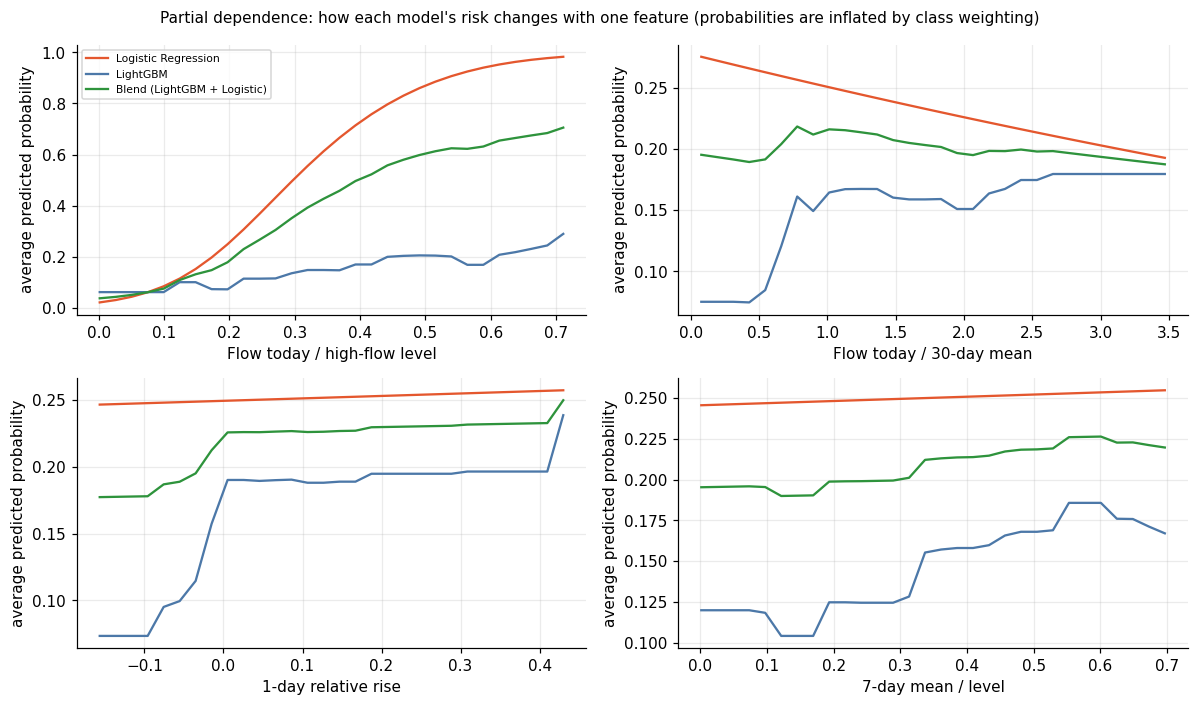

In [23]:
top4 = [c for n in imp.index[:4] for c in FEATS if NICE[c] == n]
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, c in zip(axs.ravel(), top4):
    g = np.linspace(*np.percentile(Xte[c], [2, 98]), 30); curves = {n: [] for n in NAMES}
    for v in g:
        Xg = Xte.copy(); Xg[c] = v; pl = lr_model.predict_proba(Xg)[:, 1].mean(); pg = lgb_model.predict_proba(Xg)[:, 1].mean()
        curves["Logistic Regression"].append(pl); curves["LightGBM"].append(pg); curves["Blend (LightGBM + Logistic)"].append(W*pg + (1-W)*pl)
    for n in NAMES: ax.plot(g, curves[n], color=COL[n], label=n)
    ax.set_xlabel(NICE[c]); ax.set_ylabel("average predicted probability")
axs[0, 0].legend(fontsize=7); fig.suptitle("Partial dependence: how each model's risk changes with one feature (probabilities are inflated by class weighting)", fontsize=10)
savefig("nb_11_partial_dependence.png"); plt.show()

## 6. Save the blended model for the Streamlit app

In [24]:
bundle = dict(name=f"Blend: {W:.1f} x LightGBM + {1-W:.1f} x Logistic Regression", w=W, thr=THR["Blend (LightGBM + Logistic)"], thr_lr=THR["Logistic Regression"], thr_lgb=THR["LightGBM"],
              lr=lr_model, lgbm=lgb_model, features=FEATS, nice=NICE)
joblib.dump(bundle, ROOT/"models"/"blend_model.joblib")
out = dict(weight_lightgbm=W, features=FEATS, test_days=int(len(yte)), test_onsets=int(yte.sum()), never_alert_accuracy=float(1 - yte.mean()),
           results={n: R[n] for n in NAMES}, lr_params=lr_runs[0][1], lgbm_params=lgb_runs[0][1], thresholds=THR, shap_top5=imp.head(5).round(4).to_dict())
json.dump(out, open(ROOT/"outputs"/"blend_results.json", "w"), indent=2, default=float)
te.assign(**{"p_" + n.split(" (")[0].replace(" ", "_"): P["test"][n] for n in NAMES}).to_csv(ROOT/"outputs"/"blend_test_predictions.csv", index=False)
table.round(3).to_csv(ROOT/"outputs"/"blend_comparison_table.csv")
print("saved:", bundle["name"])

saved: Blend: 0.4 x LightGBM + 0.6 x Logistic Regression


## 7. Reading the results
* **Accuracy is not the right score here.** Only about 1 % of test days are onsets, so a model that never alerts scores about 99 % accuracy and detects nothing. Use **PR-AUC and recall** (with precision) to judge the alerts.
* Compare the three bars in section 4: the blend is only worth using if its PR-AUC and recall are at least as good as the better single model. Quote the numbers from the table above, not from memory.
* The test period contains few onset events, so small differences between models are within noise.